Universidade do Vale do Itajaí<br>
Escola Politécnica<br>
Processamento Digital de Sinais: Imagens
Aluno(s):

# Exercício Avaliativo - Filtragem na Frequência e Segmentação
## Caracteres com falhas: filtros passa-baixa ideal, Butterworth e gaussiano

Nesta atividade, investigaremos como a filtragem passa-baixa no domínio da frequência influencia a segmentação de caracteres degradados. A imagem base é a [`Fig0907(a)(text_gaps_1_and_2_pixels).tif`](https://github.com/VielF/ColabProjects/blob/main/dataset/OperacaoMorfologia/Fig0907(a)(text_gaps_1_and_2_pixels).tif). A análise deverá responder a duas perguntas:

- Como Otsu, k-means e Canny representam os caracteres e suas falhas?
- Quanto a filtragem contribui para reduzir falhas indesejadas nos traços após a segmentação?

Consideramos falhas indesejadas as pequenas lacunas ou interrupções em regiões que deveriam pertencer ao traço de um caractere. Os espaços internos próprios das letras, como em “a”, “o” e “e”, devem ser preservados. Serão comparados os filtros ideal, Butterworth e gaussiano. Para cada configuração, avalie a redução das falhas e os possíveis efeitos negativos: engrossamento ou apagamento de traços, perda de espaços internos e união de caracteres próximos. 

A imagem sem filtragem será a referência de comparação do processamento: cada método deverá ser aplicado tanto à entrada original degradada quanto às versões filtradas. Não há garantia de que a filtragem melhore todos os resultados; conclusões de melhora ou piora devem ser sustentadas pelas figuras e métricas. Não utilize operações morfológicas. A entrega deverá ser realizada neste notebook, com código executado, resultados visíveis e respostas às questões propostas.

### Preparação

In [ ]:
# %pip install numpy scipy matplotlib pillow scikit-image scikit-learn pandas
import base64, io, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from scipy.ndimage import label, distance_transform_edt
from skimage.filters import threshold_otsu
from skimage.feature import canny
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from sklearn.cluster import KMeans
from IPython.display import display


Python: 3.13.11


In [ ]:
def painel(imagens, titulos, colunas=3, figsize=None):
    linhas = int(np.ceil(len(imagens) / colunas))
    fig, axs = plt.subplots(linhas, colunas, figsize=figsize or (4*colunas, 3.3*linhas), squeeze=False)
    for ax, im, titulo in zip(axs.flat, imagens, titulos):
        ax.imshow(im, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        ax.set_title(titulo); ax.axis('off')
    for ax in list(axs.flat)[len(imagens):]: ax.axis('off')
    fig.tight_layout(); plt.show()

def mostrar_recorte(imagem, x, y, largura, altura, tamanho=(10, 5)):
    recorte = imagem[y:y + altura, x:x + largura]

    plt.figure(figsize=tamanho)
    plt.imshow(recorte, cmap='gray', interpolation='nearest')
    plt.title('Recorte ampliado')
    plt.axis('off')
    plt.show()

    return recorte

### Carregamento e análise da imagem

1. Identificação das falhas e seleção dos recortes: Inspecione a imagem ampliada e selecione pelo menos três recortes:

- Uma região com falhas indesejadas nos traços.
- Uma região com espaços internos legítimos dos caracteres.
- Uma região com caracteres próximos, sujeitos à união após a filtragem.

Registre as coordenadas e utilize os mesmos recortes em todas as comparações. Marque as falhas que pretende reduzir e as estruturas que devem ser preservadas. Não considere todo pixel de fundo no interior de uma letra como defeito.

Dimensões: (444, 508)


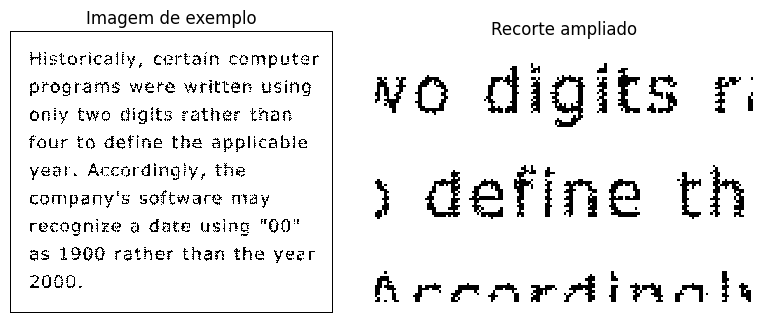

### Filtragem passa-baixa no domínio da frequência


#### Relação entre o raio do filtro e a frequência de corte

Para embasar vocês, no exercício sobre filtragem na frequência (mais especificamente nas funções) o parâmetro `radius` representa a distância ao centro do espectro, medida em posições da matriz da FFT. Esse raio corresponde ao parâmetro $D_0$ das equações dos filtros. Após aplicar `fftshift`, a frequência zero fica na posição central. Quanto mais distante desse centro, maior a frequência espacial representada.

##### Imagens quadradas

Para uma imagem de tamanho $N \times N$, cada posição da FFT corresponde a um incremento de $1/N$ ciclos por pixel. Assim, a relação entre o raio e a frequência de corte é:

$$
f_c = \frac{D_0}{N}
\qquad\Longleftrightarrow\qquad
D_0 = f_c \cdot N
$$

Nessa expressão:

- $f_c$ é a frequência de corte, em ciclos por pixel;
- $D_0$ é o raio, em posições da matriz da FFT;
- $N$ é o número de linhas ou colunas da imagem quadrada utilizada na FFT.

Por exemplo, para uma imagem de $512 \times 512$ e um raio de 35:

$$
f_c = \frac{35}{512} \approx 0{,}0684 \text{ ciclos/pixel}
$$

Portanto, a configuração `radius=35` corresponde a uma frequência de corte de aproximadamente $0{,}0684$ ciclos por pixel nessa imagem.

| Raio $D_0$ | Frequência de corte $f_c$ | Período espacial $T=1/f_c$ |
|---:|---:|---:|
| 16 | 0,03125 ciclos/pixel | 32 pixels/ciclo |
| 35 | 0,06836 ciclos/pixel | 14,63 pixels/ciclo |
| 64 | 0,125 ciclos/pixel | 8 pixels/ciclo |

O período indica o tamanho de um ciclo de uma oscilação espacial. Sendo assim, ele não representa diretamente a espessura de uma letra ou a largura de uma falha, com isso, letras, bordas e falhas contêm várias frequências.

##### Imagens retangulares

Em uma imagem com $M$ linhas e $N$ colunas, os incrementos de frequência são:

$$
\Delta f_y = \frac{1}{M}
\qquad\text{e}\qquad
\Delta f_x = \frac{1}{N}
$$

Consequentemente, um círculo de raio $D_0$ na matriz da FFT corresponde aos seguintes cortes nos eixos:

$$
f_{c,x} = \frac{D_0}{N}
\qquad\text{e}\qquad
f_{c,y} = \frac{D_0}{M}
$$

Quando $M \neq N$, esses valores são diferentes. Portanto, um círculo definido diretamente pelas posições da matriz não representa a mesma frequência de corte em todas as direções. Para definir uma frequência de corte radial em ciclos por pixel, podemos normalizar cada eixo pelas respectivas dimensões:

$$
D_f(r,c) =
\sqrt{
\left(\frac{r-r_c}{M}\right)^2 +
\left(\frac{c-c_c}{N}\right)^2
}
$$

Aqui, $(r_c,c_c)$ é o centro da FFT deslocada. Como $D_f$ está em ciclos por pixel, ele deve ser comparado diretamente com $f_c$. Nesse caso, não é necessário converter o corte para um raio inteiro. Se houver preenchimento da imagem antes da FFT, devem ser utilizadas as dimensões da matriz após esse preenchimento.

### Como escolher a frequência de corte?

A conversão entre raio e frequência é matemática, mas a escolha do melhor corte depende do objetivo do processamento. Para caracteres com pequenas falhas, podemos testar, por exemplo:

$$
f_c \in \{0{,}06;\ 0{,}10;\ 0{,}16;\ 0{,}24\}
$$

Em um filtro passa-baixa:

- Cortes menores produzem maior suavização, podendo reduzir pequenas descontinuidades, mas também apagar traços finos ou unir letras próximas.
- Cortes maiores preservam mais detalhes, mas podem manter ruído e falhas.

A comparação deve utilizar os mesmos recortes da imagem, observando tanto a saída filtrada quanto a máscara obtida após Otsu ou k-means. Uma aproximação entre traços na imagem suavizada pode se transformar em conexão somente após a segmentação. Quando existe uma referência íntegra, IoU e Dice ajudam a avaliar as máscaras de região. Sem essa referência, a escolha deve ser justificada pela análise visual, considerando recuperação das falhas, preservação dos traços e separação entre caracteres. Com isso, não existe uma conversão direta entre “falha de 2 pixels” e um único raio ideal. O resultado também depende da espessura dos traços, da proximidade entre letras, do tipo de filtro e do método de segmentação.

### O significado do corte em cada filtro

No filtro ideal, $D_0$ define uma separação abrupta: as frequências dentro do raio são preservadas e as externas são anuladas. No Butterworth e no gaussiano, a atenuação é gradual. Nas fórmulas usuais deste exercício, em $D=D_0$:

$$
H_{\text{Butterworth}}(D_0)=0{,}5
$$

$$
H_{\text{Gaussiano}}(D_0)=e^{-1/2}\approx0{,}607
$$

Assim, usar o mesmo raio nos três filtros não produz exatamente a mesma suavização.

### Centro do filtro

O centro deve corresponder à frequência zero após `fftshift`, definida pelas dimensões da matriz:

$$
r_c = \left\lfloor \frac{M}{2} \right\rfloor,
\qquad
c_c = \left\lfloor \frac{N}{2} \right\rfloor
$$

Na função `createPB` do exercício, o argumento `center` utiliza a ordem coluna e linha: `center=(cols//2, rows//2)`. A posição do maior pico do espectro não deve ser usada como regra para definir esse centro.

Seja $D=\sqrt{f_x^2+f_y^2}$, em **ciclos/pixel**, e $f_c>0$:

$$H_I(D)=\begin{cases}1&D\leq f_c\\0&D>f_c\end{cases},\quad
H_B(D)=\frac{1}{1+(D/f_c)^{2n}},\quad
H_G(D)=e^{-D^2/(2f_c^2)}.$$

O resultado é $g=\Re\{\mathcal F^{-1}[H\mathcal F(f)]\}$. Usamos `fftshift` para centralizar o espectro e `ifftshift` antes da inversa. O preenchimento por reflexão reduz o contato artificial entre bordas opostas; o recorte devolve o tamanho original. Tenha atenção, pois $f_c$ é um parâmetro de escala; os três filtros não têm o mesmo ganho em $D=f_c$. Butterworth tem ganho 0,5 e gaussiano aproximadamente 0,607. Comparar o mesmo $f_c$ não significa igualar toda a resposta espectral. O ideal pode produzir oscilações (*ringing*); o gaussiano suaviza a transição; a ordem controla a transição do Butterworth. Valores menores de $f_c$ suavizam mais. A filtragem não reconstrói de forma garantida informação perdida: a união pode surgir somente após o limiar, com risco de deformar letras.

2. Implemente os filtros ideal, Butterworth e gaussiano no domínio da frequência. Teste pelo menos duas frequências de corte por filtro e compare as ordens 1, 2 e 4 do Butterworth. Apresente as respostas dos filtros, os espectros antes e depois da filtragem e as imagens resultantes. Nos recortes selecionados, observe se a suavização aproxima os traços interrompidos e se também provoca perda de detalhes ou aproximação indevida entre caracteres. Explique as etapas da função e registre os parâmetros utilizados. Não substitua a filtragem na frequência por um filtro espacial.

**Dica**: utilize as funções disponibilizadas no exercícios sobre filtragem na frequência.

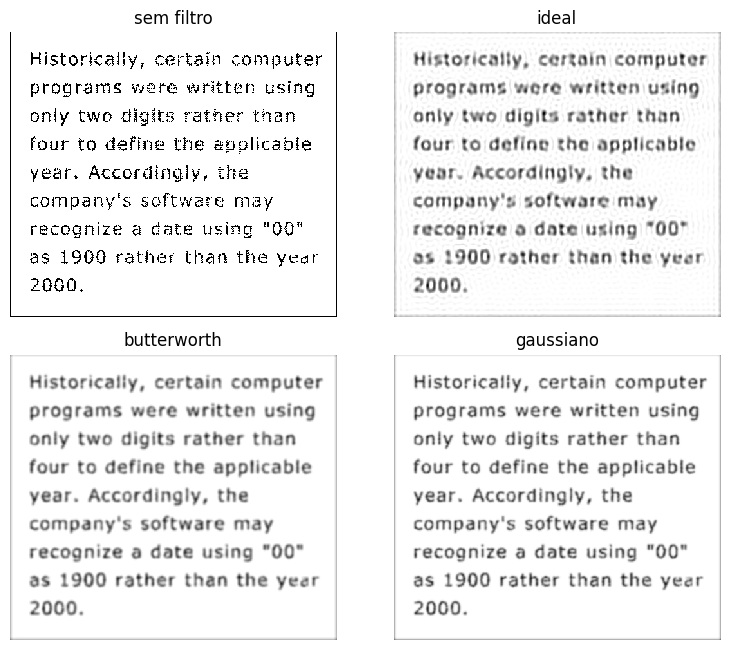

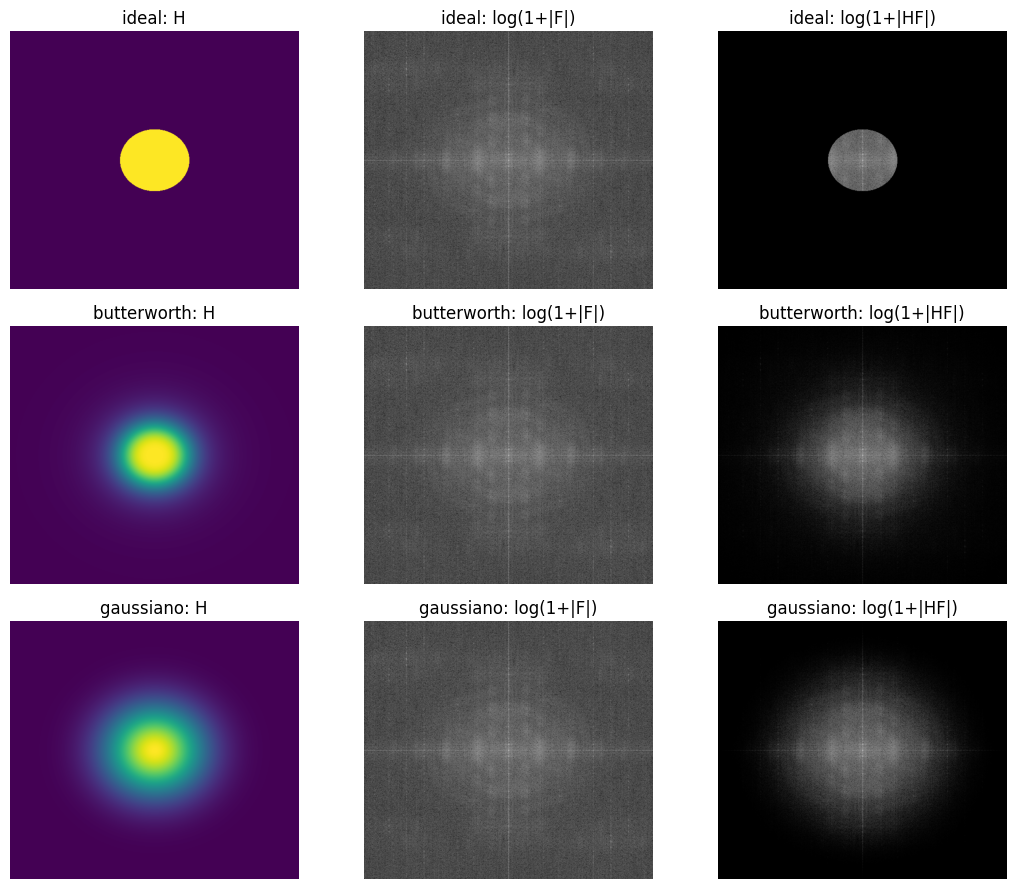

### Otsu, Canny e k-means

3. Aplique Otsu, k-means e Canny à imagem sem filtragem e a cada versão filtrada. Apresente os resultados lado a lado, utilizando os mesmos recortes e a mesma escala de exibição. Realize duas comparações:

- Entre métodos: para uma mesma imagem de entrada, compare Otsu, k-means e Canny.
- Antes e depois da filtragem: para um mesmo método, compare a entrada sem filtro com as versões filtradas.

Para Otsu e k-means, analise as máscaras de região: as falhas foram reduzidas? Os traços e espaços internos foram preservados? Houve união entre caracteres? 

Para Canny, analise os mapas de bordas: aparecem contornos adicionais ao redor das falhas? Esses contornos diminuem após a filtragem? As bordas externas dos caracteres continuam bem definidas? 

Canny produz bordas, enquanto Otsu e k-means produzem regiões. Portanto, a ausência de uma borda em uma falha não demonstra, por si só, que a região foi corretamente recuperada. Mantenha fixos os parâmetros do Canny e a configuração do k-means na comparação inicial, registrando-os. O limiar de Otsu será recalculado para cada entrada, pois faz parte do próprio método.

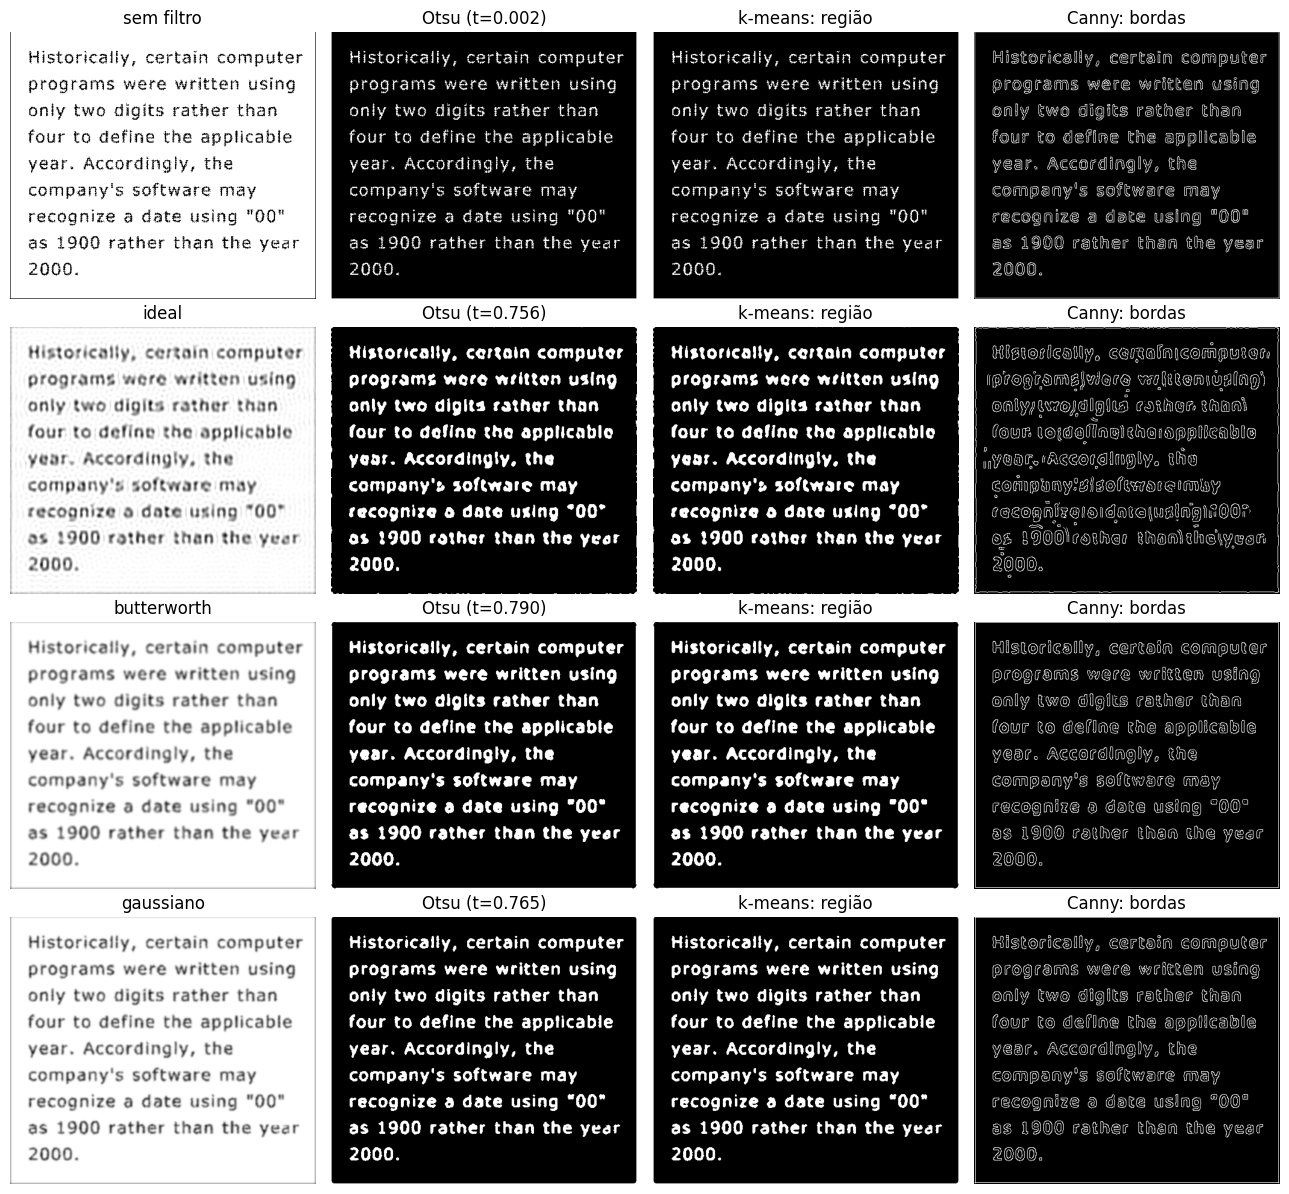

### Experimento controlado com referência conhecida

Para avaliar recuperação, criamos caracteres íntegros e apagamos pequenas faixas de 1 e 2 pixels. Acrescentamos ruído fraco com semente fixa. A degradação é uma edição direta de pixels. Use o PSNR e SSIM para medir fidelidade e [IoU e Dice](https://medium.com/mastering-data-science/understanding-evaluation-metrics-in-medical-image-segmentation-d289a373a3f) comparam regiões de texto. Para avaliar o resultado do Canny, podemos usar a métrica [F1](https://www.newroom.io/blog/top-8-metrics-to-evaluate-edge-detection-performance) de bordas, onde vocês podem utilizar a tolerância de 1,5 pixel, obtida por distância euclidiana a uma borda de referência calculada por diferenças entre vizinhos, sendo que essa tolerância permite pequenos deslocamentos. O F1 mede presença próxima, sem correspondência um a um, e deve ser acompanhado das imagens e é a única métrica recomendada para vocês compararem Otsu, k-means e Canny, sendo que IoU e Dice são boas para Otsu e k-means devido ao tipo de saída de ambos.

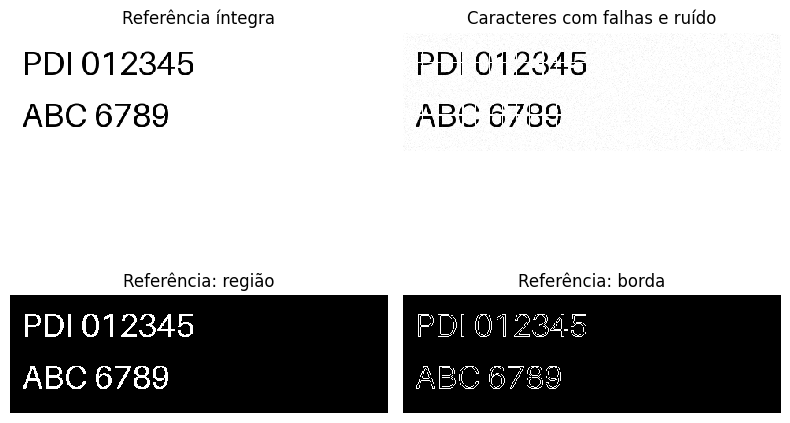

In [10]:
SEMENTE = 42

def exemplo_controlado():
    tela = Image.new('L', (480, 150), 255)
    # Fontes locais opcionais; o fallback do Pillow mantém execução sem download.
    fonte = None
    for nome in ['DejaVuSans-Bold.ttf', 'Arial.ttf']:
        try:
            fonte = ImageFont.truetype(nome, 42); break
        except OSError: pass
    if fonte is None: fonte = ImageFont.load_default(size=42)
    desenho = ImageDraw.Draw(tela)
    desenho.text((15, 12), 'PDI 012345', fill=0, font=fonte)
    desenho.text((15, 78), 'ABC 6789', fill=0, font=fonte)
    limpa = np.asarray(tela, dtype=float) / 255
    falha = limpa.copy()
    for x in range(24, 455, 17): falha[:, x:x+1+(x%2)] = 1
    falha[37:38, :] = 1; falha[103:105, :] = 1
    rng = np.random.default_rng(SEMENTE)
    degradada = np.clip(falha + rng.normal(0, 0.025, falha.shape), 0, 1)
    return limpa, degradada

def borda_por_diferencas(mask):
    # Borda interna: marca pixel de texto com vizinho ortogonal diferente.
    p = np.pad(mask, 1, constant_values=False)
    centro = p[1:-1, 1:-1]
    return centro & ((centro != p[:-2,1:-1]) | (centro != p[2:,1:-1]) |
                     (centro != p[1:-1,:-2]) | (centro != p[1:-1,2:]))

def metricas_regiao(pred, ref):
    inter = np.count_nonzero(pred & ref)
    uniao = np.count_nonzero(pred | ref)
    soma = pred.sum() + ref.sum()
    return {'IoU': inter/uniao if uniao else 1.0,
            'Dice': 2*inter/soma if soma else 1.0}

def f1_bordas(pred, ref, tolerancia=1.5):
    if not pred.any() or not ref.any():
        return float(np.array_equal(pred, ref))
    precisao = np.mean(distance_transform_edt(~ref)[pred] <= tolerancia)
    revocacao = np.mean(distance_transform_edt(~pred)[ref] <= tolerancia)
    return 2*precisao*revocacao/(precisao+revocacao) if precisao+revocacao else 0.0

limpa, degradada = exemplo_controlado()
ref_texto = limpa < 0.5
ref_borda = borda_por_diferencas(ref_texto)
painel([limpa, degradada, ref_texto, ref_borda],
       ['Referência íntegra', 'Caracteres com falhas e ruído', 'Referência: região', 'Referência: borda'], 2)

### Varredura de parâmetros e comparação com a entrada sem filtro

4. No experimento sintético, utilize a imagem íntegra e sua máscara de texto como referências. Registre também os pixels de texto apagados para produzir as falhas. Avalie:

- PSNR e SSIM: fidelidade das imagens de intensidade em relação à imagem íntegra.
- IoU e Dice: qualidade das máscaras de região produzidas por Otsu e k-means.
- F1 de bordas: qualidade dos contornos. Para comparar os três métodos, extraia as bordas das máscaras de Otsu e k-means e compare-as, junto com Canny, com a mesma borda de referência e a mesma tolerância.

Para avaliar diretamente a redução das falhas, calcule, nas máscaras de Otsu e k-means, a porcentagem dos pixels apagados que voltaram a ser classificados como texto. Compare esse valor antes e depois da filtragem.

Essa porcentagem não deve ser analisada isoladamente: uma máscara excessivamente engrossada pode recuperar os pixels apagados e também classificar o fundo como texto. Apresente falsos positivos e verifique a preservação dos espaços internos e da separação entre caracteres. Na imagem real, sem referência íntegra, apresente uma avaliação visual dos recortes marcados, sem atribuir métricas de acurácia a partir de uma referência desconhecida.

**Dica**: No texto acima, há uma explicação das métricas IoU, Dice e F1.

5. Análise final da filtragem

Para cada segmentador, identifique a configuração de filtragem com o melhor equilíbrio entre redução das falhas e preservação dos caracteres. Compare-a explicitamente com o resultado do mesmo método sem filtragem.

Responda:

- Qual método apresentou o melhor resultado sem filtragem?
- Qual combinação de filtro, parâmetros e segmentador reduziu melhor as falhas?
- A redução das falhas provocou engrossamento de traços, perda de espaços internos ou união de caracteres?

O melhor resultado de PSNR/SSIM também apresentou a melhor segmentação?

Em quais situações a filtragem piorou o resultado?

Sustente as respostas com recortes, parâmetros e métricas. Diferencie a melhor configuração observada neste experimento de uma configuração que funcionaria em outras imagens.